# Computer Vision and Image Processing
## Tìm hiểu sự khác biệt và mối liên hệ

**Mục tiêu:** giải thích xử lý ảnh và thị giác máy tính; so sánh hai lĩnh vực; phân tích cách chúng phối hợp; minh họa bằng bài toán đếm vật thể.

**Phạm vi:** tài liệu học tập được triển khai từ tiêu đề đề tài. Notebook ban đầu chưa cung cấp yêu cầu cụ thể của giảng viên, dữ liệu hoặc tiêu chí chấm điểm.

### Nội dung
1. Tổng quan và khái niệm
2. Kiến thức nền về ảnh số
3. Kỹ thuật xử lý ảnh
4. Bài toán và phương pháp thị giác máy tính
5. So sánh và mối liên hệ
6. Thực hành đếm vật thể
7. Đánh giá, hạn chế và hướng phát triển
8. Tài liệu tham khảo


## 1. Tổng quan

Đề tài trả lời bốn câu hỏi: xử lý ảnh là gì, thị giác máy tính là gì, chúng khác nhau thế nào và kết hợp ra sao?

- Làm sáng một ảnh tối: **xử lý ảnh**.
- Xác định số xe trong ảnh: **thị giác máy tính**.
- Cải thiện ảnh giao thông rồi phát hiện và đếm xe: **kết hợp cả hai**.

### 1.1. Image Processing — Xử lý ảnh

Xử lý ảnh số sử dụng thuật toán để biến đổi hoặc phân tích ảnh dưới dạng dữ liệu số. Mục tiêu có thể là tăng chất lượng, giảm nhiễu, chỉnh độ sáng và tương phản, thay đổi hình học, phân vùng hoặc chuẩn bị dữ liệu cho bước tiếp theo.

$$g(x,y)=T[f(x,y)]$$

Trong đó $f$ là ảnh đầu vào, $T$ là phép xử lý và $g$ là ảnh đầu ra. Đầu ra thường là ảnh mới, nhưng cũng có thể là histogram, đặc trưng hoặc thông số đo; không nên khẳng định đầu ra luôn là ảnh.

Ví dụ: chỉnh phối cảnh ảnh tài liệu, giảm nhiễu và nhị phân hóa để chữ dễ đọc hơn.

### 1.2. Computer Vision — Thị giác máy tính

Thị giác máy tính nghiên cứu cách suy ra thông tin về đối tượng, cấu trúc, chuyển động và ý nghĩa của cảnh từ ảnh hoặc video.

Đầu ra có thể là nhãn, tọa độ, mặt nạ đối tượng, văn bản, quỹ đạo hoặc cấu trúc 3D. Ví dụ: phát hiện người đi bộ, đọc chữ, theo dõi phương tiện và ước lượng tư thế.

Computer Vision thường được xem là một lĩnh vực của AI, nhưng **không phải mọi phương pháp đều cần học máy hoặc học sâu**. Hình học, đặc trưng thủ công và quy tắc cũng có thể giải quyết nhiều bài toán.

Tham khảo: [Microsoft — Introduction to Computer Vision](https://github.com/microsoft/AI-For-Beginners/blob/main/lessons/4-ComputerVision/06-IntroCV/README.md).


## 2. Kiến thức nền về ảnh số

### Pixel và kiểu dữ liệu

Ảnh số gồm các điểm ảnh (pixel). Ảnh xám thường có dạng ma trận $H\times W$; ảnh RGB có dạng $H\times W\times3$. Ảnh rộng 640, cao 480 pixel thường có kích thước mảng `(480, 640, 3)`.

Trong ảnh xám 8 bit, 0 thường là đen, 255 là trắng. Ảnh dùng kiểu dữ liệu khác có thể có khoảng giá trị khác. Khi tính toán cần chú ý tràn số và chuyển đổi kiểu dữ liệu.

### Không gian màu

| Không gian | Đặc điểm và ứng dụng |
|---|---|
| RGB | Ba kênh đỏ, xanh lá, xanh dương; biểu diễn màu phổ biến |
| Grayscale | Một kênh cường độ; đơn giản hóa tính toán nhưng mất thông tin màu |
| HSV | Sắc độ, độ bão hòa, độ sáng; hữu ích khi phân vùng theo màu |
| Lab | Thành phần độ sáng và màu; hữu ích cho phân tích màu |

OpenCV đọc ảnh màu theo thứ tự **BGR** mặc định; cần chuyển sang **RGB** khi hiển thị bằng Matplotlib.

### Độ phân giải và tọa độ

Độ phân giải cao thường giữ được nhiều chi tiết nhưng tăng bộ nhớ và thời gian xử lý. Trong NumPy, truy cập pixel theo `image[y, x]`; nhiều hàm hình học OpenCV nhận điểm theo `(x, y)`. Gốc tọa độ ảnh thường ở góc trên bên trái.


## 3. Những kỹ thuật xử lý ảnh quan trọng

| Kỹ thuật | Mục đích | Hạn chế cần lưu ý |
|---|---|---|
| Chuyển ảnh xám | Giảm số kênh | Mất thông tin màu |
| Resize, crop, rotate | Điều chỉnh kích thước và vùng quan tâm | Resize sai tỉ lệ gây biến dạng |
| Gaussian, lọc trung bình | Làm mượt, giảm nhiễu | Có thể làm mờ biên |
| Median | Xử lý nhiễu muối tiêu | Kernel lớn có thể mất chi tiết |
| Tăng tương phản | Làm rõ khác biệt cường độ | Có thể khuếch đại nhiễu |
| Thresholding | Tạo vùng theo ngưỡng | Nhạy với ánh sáng và nền |
| Sobel, Canny | Tìm biến đổi cường độ và biên | Biên chưa phải đối tượng |
| Hình thái học | Làm sạch, chỉnh cấu trúc vùng | Phụ thuộc kernel |
| Contour | Phân tích đường bao | Có thể bao cả nhiễu và nền |
| Biến đổi phối cảnh | Chỉnh mặt phẳng bị nghiêng | Cần điểm tương ứng phù hợp |

### 3.1. Lọc ảnh

Kernel là ma trận nhỏ được áp dụng trên các vùng lân cận. Kernel trung bình $3\times3$:

$$K=\frac{1}{9}\begin{bmatrix}1&1&1\\1&1&1\\1&1&1\end{bmatrix}$$

Pixel mới nhận giá trị trung bình của vùng lân cận. Kết quả mượt hơn nhưng có thể giảm chi tiết. Gaussian dùng trọng số theo phân bố Gaussian; median lấy trung vị thay vì trung bình.

### 3.2. Phân ngưỡng

$$B(x,y)=\begin{cases}255 & I(x,y)>T\\0 & I(x,y)\leq T\end{cases}$$

- **Ngưỡng cố định:** một ngưỡng cho toàn ảnh.
- **Otsu:** chọn ngưỡng từ histogram bằng tiêu chí phân chia hai lớp; hữu ích khi hai nhóm cường độ tách biệt tương đối rõ.
- **Ngưỡng thích nghi:** tính ngưỡng theo vùng; hữu ích khi chiếu sáng không đều.

Không có phương pháp nào phù hợp mọi ảnh.

### 3.3. Hình thái học

Với đối tượng trắng trên nền đen:

- **Erosion:** thu hẹp vùng trắng.
- **Dilation:** mở rộng vùng trắng.
- **Opening:** erosion rồi dilation; thường loại vùng trắng nhỏ.
- **Closing:** dilation rồi erosion; thường lấp lỗ hoặc khe nhỏ.

### 3.4. Contour và đặc trưng hình học

Từ đường bao có thể tính diện tích, chu vi, tâm, hộp bao và độ tròn. Độ tròn thường dùng:

$$C=\frac{4\pi A}{P^2}$$

Trong đó $A$ là diện tích và $P$ là chu vi. Hình tròn lý tưởng có $C=1$; ảnh rời rạc và cách đo có thể làm kết quả sai lệch. Đặc trưng hình học chưa đủ để xác nhận danh tính vật thể.

Nguồn thực hành: [OpenCV — Image Processing](https://docs.opencv.org/4.10.0/d7/da8/tutorial_table_of_content_imgproc.html).


## 4. Những bài toán chính của thị giác máy tính

| Bài toán | Câu hỏi | Đầu ra |
|---|---|---|
| Classification | Ảnh thuộc lớp nào? | Nhãn ảnh |
| Object detection | Có gì và ở đâu? | Nhãn, hộp bao, điểm tin cậy |
| Semantic segmentation | Mỗi pixel thuộc lớp nào? | Bản đồ lớp |
| Instance segmentation | Mỗi pixel thuộc đối tượng cụ thể nào? | Mặt nạ từng đối tượng |
| Tracking | Đối tượng di chuyển ra sao? | Mã định danh và quỹ đạo |
| OCR | Trong ảnh có chữ gì? | Văn bản |
| Pose estimation | Các khớp nằm ở đâu? | Tọa độ điểm khớp |
| Depth estimation | Cảnh có cấu trúc chiều sâu thế nào? | Bản đồ chiều sâu, có thể tương đối hoặc theo đơn vị thực |
| 3D reconstruction | Hình dạng ba chiều là gì? | Đám mây điểm hoặc mô hình 3D |

Classification thường gán nhãn toàn ảnh; detection định vị từng đối tượng; segmentation xác định vùng ở mức pixel.

### 4.1. Phương pháp truyền thống

`Ảnh → Tiền xử lý → Trích xuất đặc trưng → Quy tắc/bộ phân loại → Kết quả`

Ví dụ: phân vùng màu tìm bóng đỏ; phân tích độ tròn của contour; HOG kết hợp SVM.

Ưu điểm: dễ kiểm tra từng bước, có thể không cần dữ liệu gán nhãn lớn, phù hợp môi trường được kiểm soát. Hạn chế: cần thiết kế đặc trưng và thường nhạy với nền, ánh sáng, góc nhìn.

### 4.2. Phương pháp học sâu

`Dữ liệu và nhãn → Huấn luyện → Đánh giá → Suy luận trên ảnh mới`

CNN và Vision Transformer là các nhóm kiến trúc phổ biến. Mô hình học biểu diễn từ dữ liệu để phân loại, phát hiện hoặc phân đoạn.

Ưu điểm: học đặc trưng phức tạp và xử lý nhiều biến thiên. Hạn chế: phụ thuộc dữ liệu, tài nguyên, cách huấn luyện; khó giải thích đầy đủ; có thể giảm hiệu quả khi môi trường thay đổi.

Mô hình vẫn cần chuẩn bị đầu vào đúng quy cách. Tăng cường ảnh thủ công không mặc nhiên cải thiện kết quả; phải kiểm chứng trên nhiệm vụ thực tế.


## 5. So sánh và mối liên hệ

| Tiêu chí | Xử lý ảnh | Thị giác máy tính |
|---|---|---|
| Trọng tâm | Biến đổi và phân tích dữ liệu ảnh | Suy ra thông tin về cảnh |
| Câu hỏi | Làm ảnh rõ hơn như thế nào? | Có gì, ở đâu, đang làm gì? |
| Đầu ra phổ biến | Ảnh mới, biên, histogram, đặc trưng | Nhãn, vị trí, chuyển động, chiều sâu |
| Phương pháp | Bộ lọc, biến đổi hình học, ngưỡng, hình thái học | Hình học, đặc trưng, học máy, học sâu |
| Huấn luyện | Nhiều phương pháp không cần | Tùy phương pháp |
| Ví dụ | Khử nhiễu | Phát hiện xe |

**Ranh giới không tuyệt đối:** phân đoạn, tìm biên và trích xuất đặc trưng có thể thuộc cả hai tùy mục đích. Tìm biên để tạo ảnh nét là xử lý ảnh; sử dụng biên để đo kích thước sản phẩm là một bước trong hệ thống thị giác.

### Quy trình kết hợp

```text
Thu nhận ảnh
    ↓
Tiền xử lý
    ↓
Trích xuất hoặc học đặc trưng
    ↓
Nhận diện, phát hiện hoặc đo lường
    ↓
Hậu xử lý
    ↓
Thông tin phục vụ ứng dụng
```

Không phải ứng dụng nào cũng cần đầy đủ các bước. Xử lý ảnh có thể xuất hiện trước, trong và sau quá trình suy luận.

### Ví dụ: đọc biển số

| Bước | Công việc |
|---|---|
| Thu nhận | Chụp ảnh phương tiện |
| Tiền xử lý | Resize, giảm nhiễu khi cần |
| Phát hiện | Tìm vị trí biển số |
| Chuẩn hóa | Cắt và chỉnh phối cảnh |
| Nhận dạng | Đọc ký tự |
| Hậu xử lý | Kiểm tra định dạng và tổng hợp kết quả |

### Ứng dụng khác

- Công nghiệp: phát hiện lỗi bề mặt, đo kích thước.
- Nông nghiệp: phân tích cây trồng, đếm quả.
- Tài liệu: quét trang, đọc chữ, trích xuất thông tin.
- Giao thông: đếm xe và theo dõi chuyển động.
- Y sinh: hỗ trợ phân tích ảnh; yêu cầu đánh giá chuyên biệt trước ứng dụng thực tế.


## 6. Thực hành: phát hiện và đếm vật thể trên nền đơn giản

### Mục tiêu

Quan sát kết quả từng phép xử lý, sau đó suy ra số vùng và vị trí. Dùng hình tròn giấy hoặc đồng xu tách rời trên nền tương phản.

`Ảnh màu → Ảnh xám → Gaussian blur → Otsu → Opening → Contour → Lọc diện tích → Đếm`

### Chuẩn bị

- Môi trường cần các gói `opencv-python`, `numpy`, `matplotlib`.
- Nếu thiếu, chạy trong một ô riêng: `%pip install opencv-python numpy matplotlib`, rồi khởi động lại kernel nếu cần.
- Ô tiếp theo mặc định tạo ảnh mô phỏng để có thể chạy mà không cần tệp ảnh ngoài.
- Để thử ảnh thật, đặt `USE_SYNTHETIC = False` và lưu `objects.jpg` cùng thư mục notebook.

**Giả định:** vật thể tối trên nền sáng, tách rời nhau, tương phản đủ rõ. Code đếm vùng thỏa điều kiện, chưa xác nhận đó là đồng xu hoặc loại vật thể cụ thể.


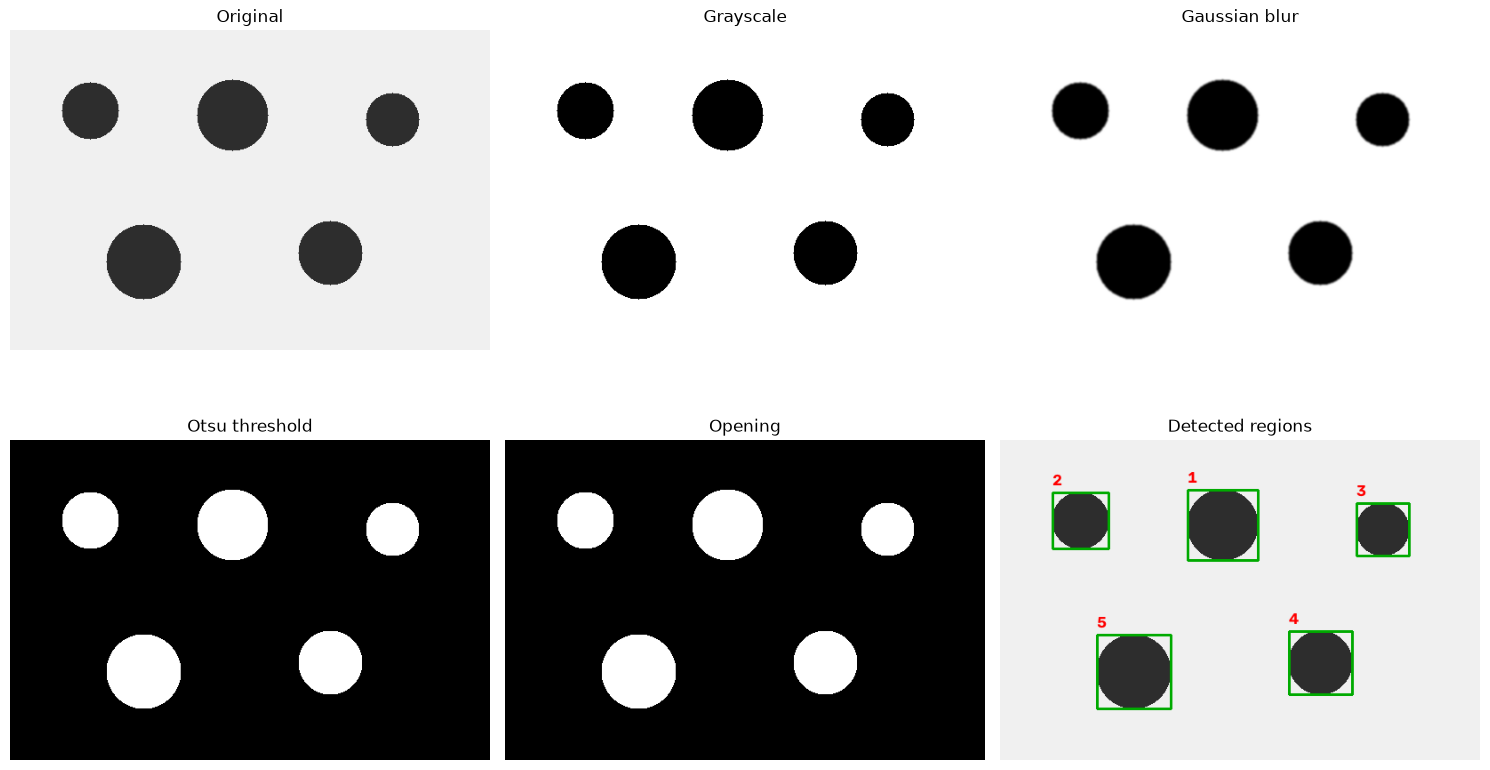

Ngưỡng Otsu: 132.0
Số vùng được phát hiện: 5
Số vật thể thực tế: 5
Sai số tuyệt đối: 0


In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

USE_SYNTHETIC = True
IMAGE_PATH = Path("objects.jpg")
MIN_AREA = 300  # Điều chỉnh theo độ phân giải và kích thước vật thể.

if USE_SYNTHETIC:
    image = np.full((360, 540, 3), 240, dtype=np.uint8)
    circles = [(90, 90, 32), (250, 95, 40), (430, 100, 30),
               (150, 260, 42), (360, 250, 36)]
    for x, y, radius in circles:
        cv2.circle(image, (x, y), radius, (45, 45, 45), -1)
    expected_count = len(circles)
else:
    if not IMAGE_PATH.is_file():
        raise FileNotFoundError(f"Không tìm thấy ảnh: {IMAGE_PATH.resolve()}")
    image = cv2.imdecode(
        np.fromfile(IMAGE_PATH, dtype=np.uint8), cv2.IMREAD_COLOR
    )
    if image is None:
        raise ValueError(f"Không thể giải mã ảnh: {IMAGE_PATH}")
    expected_count = None  # Điền số đếm thủ công nếu muốn đối chiếu.

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
threshold_value, binary = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
kernel = np.ones((3, 3), dtype=np.uint8)
cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
contours, _ = cv2.findContours(
    cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
valid_contours = sorted(
    (c for c in contours if cv2.contourArea(c) >= MIN_AREA),
    key=lambda c: (cv2.boundingRect(c)[1], cv2.boundingRect(c)[0]),
)

result = image.copy()
for index, contour in enumerate(valid_contours, start=1):
    x, y, width, height = cv2.boundingRect(contour)
    cv2.rectangle(result, (x, y), (x + width, y + height), (0, 170, 0), 2)
    cv2.putText(result, str(index), (x, max(y - 8, 18)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

stages = [
    (cv2.cvtColor(image, cv2.COLOR_BGR2RGB), "Original"),
    (gray, "Grayscale"),
    (blurred, "Gaussian blur"),
    (binary, "Otsu threshold"),
    (cleaned, "Opening"),
    (cv2.cvtColor(result, cv2.COLOR_BGR2RGB), "Detected regions"),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for axis, (stage, title) in zip(axes.ravel(), stages):
    axis.imshow(stage, cmap="gray" if stage.ndim == 2 else None)
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

predicted_count = len(valid_contours)
print(f"Ngưỡng Otsu: {threshold_value:.1f}")
print(f"Số vùng được phát hiện: {predicted_count}")
if expected_count is not None:
    print(f"Số vật thể thực tế: {expected_count}")
    print(f"Sai số tuyệt đối: {abs(predicted_count - expected_count)}")


### 6.1. Phân tích kết quả thực hành

Ảnh mô phỏng chứa **5 hình tròn**. Đây là số lượng thiết kế của dữ liệu; cần chạy code để xem số vùng thuật toán thực sự phát hiện.

- Chuyển xám và Gaussian giúp đơn giản hóa và làm mượt dữ liệu.
- Otsu tạo mặt nạ đối tượng trắng trên nền đen.
- Opening loại các vùng trắng nhỏ, nhưng cũng có thể xóa chi tiết hữu ích.
- Contour xác định các vùng liên thông bên ngoài.
- Lọc diện tích loại một số vùng nhỏ; ngưỡng này phụ thuộc độ phân giải.
- Đếm các vùng là bước suy ra thông tin từ ảnh.

### 6.2. Thí nghiệm nên thực hiện

1. Đổi kích thước kernel Gaussian và quan sát biên.
2. Đổi `MIN_AREA` để thấy ảnh hưởng của tham số.
3. Cho hai hình tròn chạm nhau; kiểm tra có bị gộp thành một vùng không.
4. Thêm bóng đổ hoặc nền có họa tiết.
5. Thử vật thể sáng trên nền tối và đổi `THRESH_BINARY_INV` thành `THRESH_BINARY`.

Ghi lại ảnh đầu vào, tham số, số đếm thật, số đếm dự đoán và nguyên nhân sai. Thành công trên ảnh mô phỏng chưa chứng minh phương pháp tốt với ảnh thực tế.


## 7. Đánh giá kết quả

| Nhiệm vụ | Chỉ số hoặc cách kiểm tra |
|---|---|
| Khôi phục ảnh | MSE, PSNR, SSIM khi có ảnh tham chiếu phù hợp |
| Phân loại | Accuracy, precision, recall, F1, confusion matrix |
| Phát hiện | Precision, recall, AP/mAP với quy tắc ghép và ngưỡng IoU xác định |
| Phân đoạn | IoU, Dice |
| Đếm | Sai số tuyệt đối, MAE |
| Thời gian thực | Độ trễ, FPS trên phần cứng xác định |

### Một số công thức

$$Precision=\frac{TP}{TP+FP},\qquad Recall=\frac{TP}{TP+FN}$$

$$F1=\frac{2PR}{P+R}$$

Trong đó $TP$ là dự đoán dương đúng, $FP$ là dương giả, $FN$ là bỏ sót. Cần quy định cách xử lý trường hợp mẫu số bằng 0.

$$IoU=\frac{|A\cap B|}{|A\cup B|}$$

$A,B$ có thể là vùng dự đoán và vùng chuẩn. Với bài toán đếm:

$$MAE=\frac{1}{N}\sum_{i=1}^{N}|\hat{c}_i-c_i|$$

$N$ là số ảnh; $\hat{c}_i$ là số dự đoán; $c_i$ là số thực tế. Sai số đếm nhỏ vẫn có thể che giấu việc bỏ sót và đếm nhầm bù trừ nhau; nên quan sát cả vị trí phát hiện.

### Thiết kế đánh giá

- Kiểm tra nhiều ảnh với ánh sáng, nền, kích thước và mức che khuất khác nhau.
- So sánh trước và sau mỗi bước xử lý.
- Nếu dùng học máy: tách tập huấn luyện, xác thực và kiểm tra; tránh rò rỉ dữ liệu hoặc ảnh gần trùng giữa các tập.
- Không điều chỉnh tham số liên tục dựa trên tập kiểm tra cuối cùng.
- Báo cáo cả trường hợp thất bại, tốc độ và điều kiện thực nghiệm.

| Ảnh | Điều kiện | Số thật | Số dự đoán | Sai số | Nhận xét |
|---|---|---|---|---|---|
| Mô phỏng | Nền sáng, vật thể tách rời | 5 | Điền sau khi chạy | Điền sau khi chạy | Kiểm tra cơ bản |
| Ảnh thực 1 | Tự mô tả | … | … | … | … |
| Ảnh thực 2 | Tự mô tả | … | … | … | … |


## 8. Khó khăn, hạn chế và hướng phát triển

### Khó khăn chung

- Ánh sáng, góc nhìn và kích thước làm thay đổi biểu hiện của cùng một vật thể.
- Che khuất khiến thiếu thông tin.
- Nền phức tạp gây phát hiện nhầm.
- Nhiễu và nhòe làm mất chi tiết.
- Dữ liệu triển khai khác dữ liệu huấn luyện có thể làm giảm hiệu quả.
- Tốc độ, bộ nhớ và điện năng giới hạn lựa chọn thuật toán.
- Gán nhãn tốn thời gian và có thể sai hoặc thiên lệch.
- Với ảnh con người, cần xem xét quyền riêng tư và phạm vi sử dụng dữ liệu.

### Hướng mở rộng bài thực hành

- Thêm lọc hình dạng và độ tròn khi đối tượng có hình học phù hợp.
- Thử ngưỡng thích nghi khi ánh sáng không đều.
- Nghiên cứu distance transform và watershed để tách vật thể chạm nhau.
- Dùng mô hình phát hiện hoặc phân đoạn khi nền và hình dạng phức tạp.
- Xây dựng bộ ảnh đa dạng, có số đếm và nhãn chuẩn để đánh giá.

### Những nhận định cần tránh

| Nhận định sai hoặc thiếu | Cách hiểu phù hợp |
|---|---|
| Computer Vision chính là Image Processing | Có giao thoa nhưng khác trọng tâm |
| Computer Vision luôn dùng Deep Learning | Có phương pháp truyền thống và học sâu |
| Xử lý ảnh chỉ để làm ảnh đẹp | Còn phục vụ đo lường, khôi phục và phân tích |
| Có contour là đã nhận diện được vật thể | Contour chủ yếu cung cấp hình học |
| Ảnh rõ hơn chắc chắn làm mô hình tốt hơn | Cần đo hiệu quả trên nhiệm vụ cụ thể |
| Đúng một ảnh là thuật toán tốt | Cần thử nhiều điều kiện |


## 9. Đề cương báo cáo và kết luận

### Bố cục báo cáo đề xuất

1. Giới thiệu: lý do chọn đề tài, mục tiêu và phạm vi.
2. Cơ sở ảnh số: pixel, màu, độ phân giải và kiểu dữ liệu.
3. Xử lý ảnh: khái niệm, kỹ thuật và ví dụ.
4. Thị giác máy tính: bài toán và phương pháp.
5. So sánh: khác biệt, giao thoa và các hiểu lầm.
6. Mối liên hệ: phân tích quy trình ứng dụng.
7. Thực nghiệm: dữ liệu, code, tham số, ảnh kết quả.
8. Đánh giá: chỉ số, thành công, thất bại và giới hạn.
9. Kết luận và hướng phát triển.
10. Tài liệu tham khảo.

Với tiêu đề hiện tại, phần **khác biệt và mối liên hệ** là trọng tâm. Học sâu là nội dung mở rộng, không bắt buộc phải huấn luyện mô hình phức tạp để minh họa đề tài.

### Kết luận

Xử lý ảnh cung cấp các phương pháp biến đổi và phân tích dữ liệu hình ảnh. Thị giác máy tính sử dụng thông tin thị giác để suy ra đặc điểm của thế giới. Hai lĩnh vực thường phối hợp trong cùng một ứng dụng; việc chọn thuật toán phải dựa trên mục tiêu, dữ liệu và đánh giá thực nghiệm.

## 10. Tài liệu tham khảo

1. [OpenCV — Image Processing](https://docs.opencv.org/4.10.0/d7/da8/tutorial_table_of_content_imgproc.html): kỹ thuật xử lý ảnh và ví dụ thực hành.
2. [Microsoft — Introduction to Computer Vision](https://github.com/microsoft/AI-For-Beginners/blob/main/lessons/4-ComputerVision/06-IntroCV/README.md): tài liệu nhập môn.
3. [OpenCV — Fundamentals of Computer Vision & Image Processing](https://opencv.org/pdf/Curriculum-Fundamentals-of-Computer-Vision-Image-Processing-OpenCV.pdf): đề cương học tập tham khảo.

**Ghi chú thực nghiệm:** notebook cung cấp mã minh họa; các ô code chưa có kết quả thực thi được lưu. Chạy các ô theo thứ tự để tạo và kiểm tra kết quả trong môi trường của bạn.
